# 01 — Post-Phase14 Proposal Root-Cause Diagnostic

This is a reproducibility notebook for the completed post-Phase14 causal decomposition.
It loads saved JSON/CSV artifacts only. It does not retrain, run inference, access TEST,
start Phase 15, or perform H3 training/evaluation.

Phase-14 terminal state: `DIAGNOSTIC_PROPOSAL_BOTTLENECK`.
Final root-cause classification: `F_MIXED_BOTTLENECK`.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def discover_repo(start=None):
    candidates = []
    if start is not None:
        candidates.append(Path(start).resolve())
    candidates.extend([Path.cwd().resolve(), Path.cwd().resolve().parent])
    try:
        candidates.append(Path(__file__).resolve())
    except NameError:
        pass
    for candidate in candidates:
        current = candidate if candidate.is_dir() else candidate.parent
        for root in (current, *current.parents):
            if all((root / name).is_dir() for name in ("scripts", "reports", "manifests", "notebooks")):
                return root
    fallback = Path(r"D:/Softfors/jup")
    if all((fallback / name).is_dir() for name in ("scripts", "reports", "manifests", "notebooks")):
        return fallback
    raise RuntimeError("Repository root not found: expected scripts/, reports/, manifests/, notebooks/.")

ROOT = discover_repo()
AUDITS = ROOT / "reports" / "audits"
TABLES = ROOT / "reports" / "tables"

def load_json(relative):
    with (ROOT / relative).open("r", encoding="utf-8") as handle:
        return json.load(handle)

def read_csv(relative):
    return pd.read_csv(ROOT / relative)

def sha(relative):
    return hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()

print("Repository root:", ROOT)
print("No training or inference is executed by this notebook.")

Repository root: D:\Softfors\jup
No training or inference is executed by this notebook.


In [2]:
root_cause = load_json("reports/audits/phase14_diag_root_cause.json")
mode_summary = read_csv("reports/tables/phase14_clean_v3_mode_summary.csv")
proposal_by_stratum = root_cause["section5_proposal_supply"]["by_stratum"]
print("Population:", root_cause["population"])
print("Frozen proposal policy: threshold=0.10, margin=0.20, top_k=5, NMS IoU=0.30")

Population: {'val_images': 103, 'components': 152, 'strata': {'TINY': 72, 'SMALL': 28, 'MEDIUM': 36, 'LARGE': 16}}
Frozen proposal policy: threshold=0.10, margin=0.20, top_k=5, NMS IoU=0.30


## 1. Population and proposal supply

In [3]:
strata = list(proposal_by_stratum)
supply = pd.DataFrame([
    {
        "stratum": s,
        **proposal_by_stratum[s],
    }
    for s in strata
])
display(supply[[
    "stratum", "n_components", "zero_proposal_components", "zero_proposal_rate",
    "proposal_recall_any_overlap", "proposal_recall_cov_ge_0.50",
    "proposal_recall_cov_ge_0.90", "best_proposal_coverage_mean",
    "best_proposal_coverage_median", "best_proposal_bbox_iou_mean",
]])
overall = root_cause["section5_proposal_supply"]["overall"]
overall_table = pd.DataFrame([
    ("total proposals", overall["n_proposals_total"]),
    ("proposals/image mean", overall["proposals_per_image_mean"]),
    ("proposals/image median", overall["proposals_per_image_median"]),
    ("proposals/image p90", overall["proposals_per_image_p90"]),
    ("TP proposals", overall["n_tp_proposals"]),
    ("TP fraction (%)", overall["proposal_precision_TP_fraction"]),
    ("background FP proposals", overall["n_fp_background_proposals"]),
    ("background FP fraction (%)", overall["background_proposal_fraction"]),
    ("duplicate proposals", overall["n_duplicate_proposals"]),
    ("duplicate burden (%)", overall["duplicate_proposal_rate"]),
    ("zero-proposal GT components", sum(proposal_by_stratum[s]["zero_proposal_components"] for s in strata)),
], columns=["metric", "value"])
display(overall_table)

,stratum,n_components,zero_proposal_components,zero_proposal_rate,proposal_recall_any_overlap,proposal_recall_cov_ge_0.50,proposal_recall_cov_ge_0.90,best_proposal_coverage_mean,best_proposal_coverage_median,best_proposal_bbox_iou_mean
0,TINY,72,57,79.17,20.83,20.83,20.83,0.2079,0.0000,0.0463
1,SMALL,28,13,46.43,53.57,53.57,46.43,0.5189,0.7679,0.1620
2,MEDIUM,36,6,16.67,83.33,83.33,66.67,0.7904,1.0000,0.3858
3,LARGE,16,3,18.75,81.25,75.00,50.00,0.7006,0.9206,0.3732


,metric,value
0,total proposals,514.0000
1,proposals/image mean,4.9903
2,proposals/image median,5.0000
3,proposals/image p90,5.0000
4,TP proposals,74.0000
5,TP fraction (%),14.4000
6,background FP proposals,440.0000
7,background FP fraction (%),85.6000
8,duplicate proposals,6.0000
9,duplicate burden (%),1.1700


## 2. Supply recall, geometry, and conditional refiner behavior

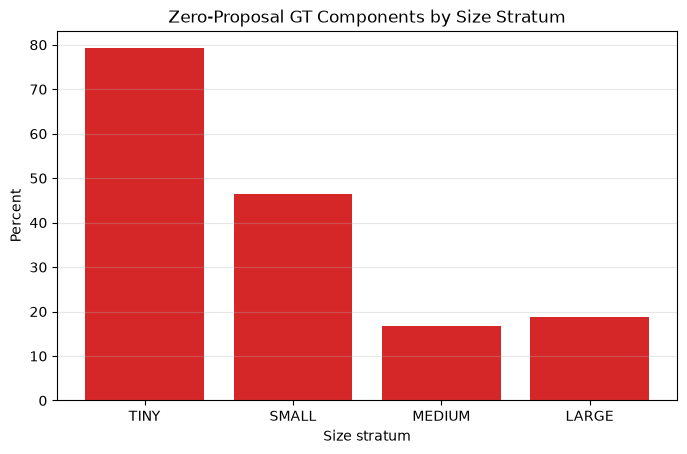

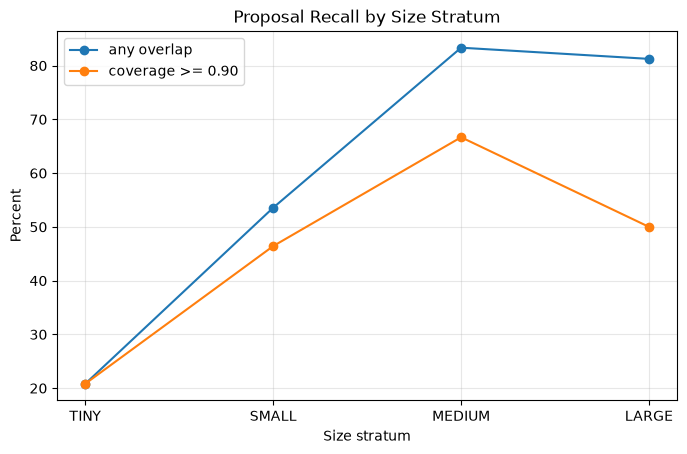

,value
n_components_with_proposal,73.000000
center_displacement_px_mean,27.753000
center_displacement_px_median,21.225000
width_ratio_pred_over_oracle_mean,1.387400
height_ratio_pred_over_oracle_mean,1.387400
area_ratio_pred_over_oracle_mean,2.538000
gt_coverage_in_predicted_roi_mean,0.947400
gt_coverage_in_predicted_roi_median,1.000000
fraction_predicted_roi_contains_enough_context_ge_0.90,82.190000
excess_background_area_fraction_mean,0.002585


,coverage_stratum,n_components,mean_best_proposal_coverage,predicted_cov90_rate,mean_predicted_coverage_ratio,mean_refiner_crop_iou,mean_refiner_crop_coverage,refiner_improves_global_rate,mean_oracle_sel_coverage_ratio,mean_fp_removed_coverage_ratio
0,COV_GE_0.90,60,0.9955,53.33,0.8631,0.5518,0.8621,55.00,0.8631,0.8631
1,COV_0.50_0.90,12,0.7760,0.00,0.4651,0.3561,0.3910,66.67,0.4731,0.4651
2,COV_LT_0.50,1,0.1175,0.00,0.0559,0.0245,0.0245,100.00,0.0245,0.0559
3,NO_MATCHED_PROPOSAL,79,0.0000,15.19,0.5750,0.0000,0.0000,35.44,0.5750,0.5750


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(supply["stratum"], supply["zero_proposal_rate"], color="tab:red")
ax.set(title="Zero-Proposal GT Components by Size Stratum", xlabel="Size stratum", ylabel="Percent")
ax.grid(True, axis="y", alpha=0.3); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(supply["stratum"], supply["proposal_recall_any_overlap"], marker="o", label="any overlap")
ax.plot(supply["stratum"], supply["proposal_recall_cov_ge_0.90"], marker="o", label="coverage >= 0.90")
ax.set(title="Proposal Recall by Size Stratum", xlabel="Size stratum", ylabel="Percent")
ax.grid(True, alpha=0.3); ax.legend(); plt.show()

geometry = pd.DataFrame([root_cause["section6_geometry_bridge"]])
display(geometry.T.rename(columns={0: "value"}))
conditional = []
for key, value in root_cause["section7_conditional_refiner"]["by_coverage_stratum"].items():
    conditional.append({"coverage_stratum": key, **value})
display(pd.DataFrame(conditional))

,coverage stratum,components,mean best proposal coverage,mean refiner crop coverage,refiner improves global rate (%)
0,COV_GE_0.90,60,0.9955,0.8621,55.00
1,COV_0.50_0.90,12,0.7760,0.3910,66.67
2,COV_LT_0.50,1,0.1175,0.0245,100.00
3,NO_MATCHED_PROPOSAL,79,0.0000,0.0000,35.44


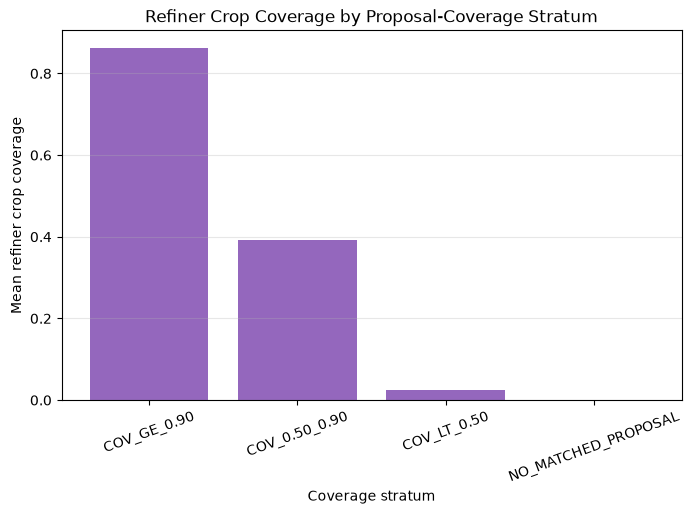

In [5]:
coverage = pd.DataFrame([
    ("COV_GE_0.90", 60, 0.9955, 0.8621, 55.0),
    ("COV_0.50_0.90", 12, 0.7760, 0.3910, 66.67),
    ("COV_LT_0.50", 1, 0.1175, 0.0245, 100.0),
    ("NO_MATCHED_PROPOSAL", 79, 0.0, 0.0, 35.44),
], columns=["coverage stratum", "components", "mean best proposal coverage",
            "mean refiner crop coverage", "refiner improves global rate (%)"])
display(coverage)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(coverage["coverage stratum"], coverage["mean refiner crop coverage"], color="tab:purple")
ax.set(title="Refiner Crop Coverage by Proposal-Coverage Stratum",
       xlabel="Coverage stratum", ylabel="Mean refiner crop coverage")
ax.tick_params(axis="x", rotation=20); ax.grid(True, axis="y", alpha=0.3); plt.show()

## 3. Counterfactual comparisons

,condition,mean Dice
0,GLOBAL_ONLY,0.6359
1,PREDICTED,0.4185
2,ORACLE_SEL,0.6304
3,FP_REMOVED,0.6288


,condition,FP components/image
0,PREDICTED,7.7767
1,ORACLE_SEL,0.6796
2,FP_REMOVED,0.6893


,overall,TINY,SMALL,MEDIUM,LARGE,hard_tiny_recovered,hard_tiny_total
GLOBAL,82.24,79.17,82.14,86.11,87.50,0.0,15.0
PREDICTED,87.50,79.17,89.29,100.00,93.75,0.0,15.0
ORACLE_SEL,87.50,79.17,89.29,100.00,93.75,0.0,15.0
FP_REMOVED,87.50,79.17,89.29,100.00,93.75,0.0,15.0


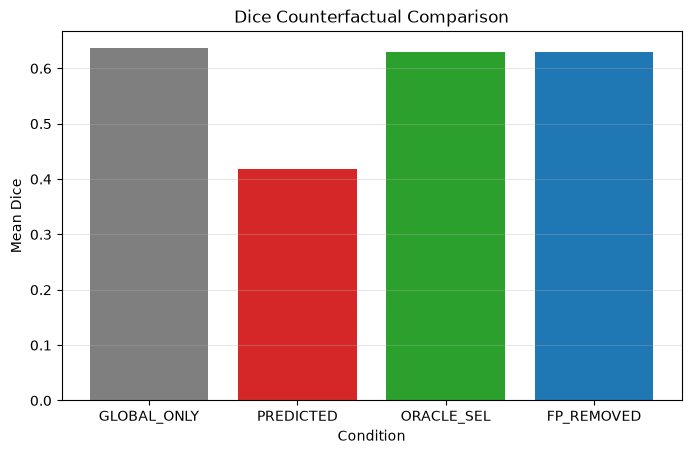

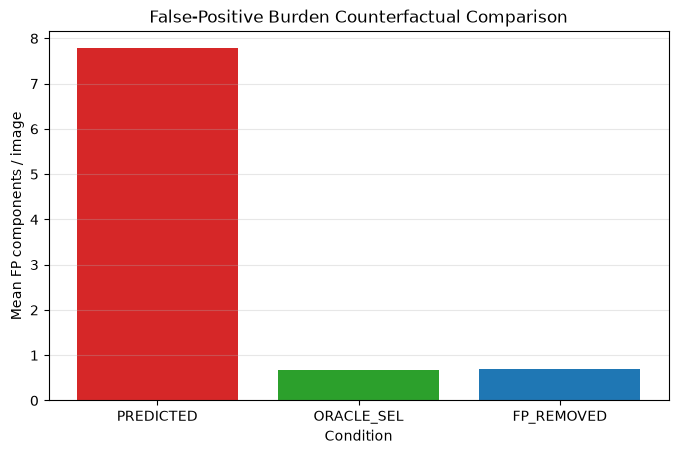

In [6]:
counter = root_cause["section8_counterfactuals"]
dice = pd.DataFrame({
    "condition": ["GLOBAL_ONLY", "PREDICTED", "ORACLE_SEL", "FP_REMOVED"],
    "mean Dice": [
        counter["image_dice"]["GLOBAL_ONLY_mean"],
        counter["image_dice"]["PREDICTED_mean"],
        counter["image_dice"]["ORACLE_SEL_mean"],
        counter["image_dice"]["FP_REMOVED_mean"],
    ],
})
display(dice)
fp = pd.DataFrame({
    "condition": ["PREDICTED", "ORACLE_SEL", "FP_REMOVED"],
    "FP components/image": [counter["fp_burden"][f"{x}_mean"] for x in ["PREDICTED", "ORACLE_SEL", "FP_REMOVED"]],
})
display(fp)
recall = pd.DataFrame(counter["component_recall90"]).T
display(recall)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(dice["condition"], dice["mean Dice"], color=["tab:gray", "tab:red", "tab:green", "tab:blue"])
ax.set(title="Dice Counterfactual Comparison", xlabel="Condition", ylabel="Mean Dice")
ax.grid(True, axis="y", alpha=0.3); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(fp["condition"], fp["FP components/image"], color=["tab:red", "tab:green", "tab:blue"])
ax.set(title="False-Positive Burden Counterfactual Comparison",
       xlabel="Condition", ylabel="Mean FP components / image")
ax.grid(True, axis="y", alpha=0.3); plt.show()

## 4. Mechanism attribution and terminal interpretation

,mechanism,score,role
0,A_PROPOSAL_SUPPLY_RECALL_LIMITATION,0.5197,primary
1,B_PROPOSAL_GEOMETRY_LIMITATION,0.0855,refuted
2,C_PROPOSAL_CONTAMINATION_LIMITATION,0.8560,secondary
3,D_PROPOSAL_RANKING_LIMITATION,0.0000,refuted
4,E_REFINER_DOMAIN_SHIFT_ON_PREDICTED_CROPS,0.0000,refuted


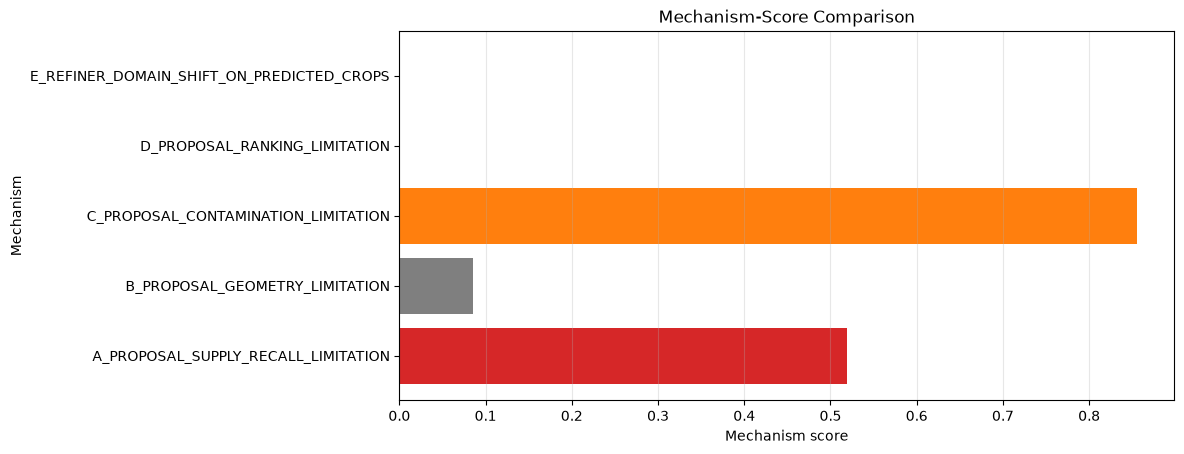

Dominant: F_MIXED_BOTTLENECK
Primary: A_PROPOSAL_SUPPLY_RECALL_LIMITATION
Secondary: C_PROPOSAL_CONTAMINATION_LIMITATION
TEST: CLOSED; Phase 15: NOT_STARTED_AND_NOT_AUTHORIZED


In [7]:
attribution = root_cause["section9_failure_attribution"]
mechanism = pd.DataFrame([
    ("A_PROPOSAL_SUPPLY_RECALL_LIMITATION", attribution["mechanism_scores"]["A_PROPOSAL_SUPPLY_RECALL_LIMITATION"], "primary"),
    ("B_PROPOSAL_GEOMETRY_LIMITATION", attribution["mechanism_scores"]["B_PROPOSAL_GEOMETRY_LIMITATION"], "refuted"),
    ("C_PROPOSAL_CONTAMINATION_LIMITATION", attribution["mechanism_scores"]["C_PROPOSAL_CONTAMINATION_LIMITATION"], "secondary"),
    ("D_PROPOSAL_RANKING_LIMITATION", attribution["mechanism_scores"]["D_PROPOSAL_RANKING_LIMITATION"], "refuted"),
    ("E_REFINER_DOMAIN_SHIFT_ON_PREDICTED_CROPS", attribution["mechanism_scores"]["E_REFINER_DOMAIN_SHIFT_ON_PREDICTED_CROPS"], "refuted"),
], columns=["mechanism", "score", "role"])
display(mechanism)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(mechanism["mechanism"], mechanism["score"], color=["tab:red", "tab:gray", "tab:orange", "tab:gray", "tab:gray"])
ax.set(title="Mechanism-Score Comparison", xlabel="Mechanism score", ylabel="Mechanism")
ax.grid(True, axis="x", alpha=0.3); plt.show()
print("Dominant:", attribution["dominant_mechanism"])
print("Primary:", attribution["primary_mechanism"])
print("Secondary:", attribution["secondary_mechanism"])
assert attribution["dominant_mechanism"] == "F_MIXED_BOTTLENECK"
assert attribution["primary_mechanism"] == "A_PROPOSAL_SUPPLY_RECALL_LIMITATION"
assert attribution["secondary_mechanism"] == "C_PROPOSAL_CONTAMINATION_LIMITATION"
assert root_cause["governance"]["test_split_reads"] == 0
assert root_cause["governance"].get("external_test_reads", 0) == 0
assert root_cause["governance"].get("external_data_used", False) is False
print("TEST: CLOSED; Phase 15: NOT_STARTED_AND_NOT_AUTHORIZED")

## 5. Provenance and boundary

In [8]:
provenance_paths = [
    "reports/audits/phase14_diag_root_cause.json",
    "reports/tables/phase14_diag_proposal_level.csv",
    "reports/tables/phase14_diag_component_level.csv",
    "reports/tables/phase14_diag_geometry_bridge.csv",
    "reports/tables/phase14_diag_conditional_refiner.csv",
    "reports/tables/phase14_clean_v3_mode_summary.csv",
]
display(pd.DataFrame([{"path": p, "SHA-256": sha(p)} for p in provenance_paths]))
print("No new inference or training was performed.")

,path,SHA-256
0,reports/audits/phase14_diag_root_cause.json,dd9b5b86ab1933e766ad01c33f672d096a334710781382...
1,reports/tables/phase14_diag_proposal_level.csv,7632a261f647d016feafde80b887769aa631bc3a935846...
2,reports/tables/phase14_diag_component_level.csv,59605f3b05c34031cadcfc8b39160a330d4b6e70fe87ab...
3,reports/tables/phase14_diag_geometry_bridge.csv,2327a109a46f5c9ebc9edbed1609e669ed8a0baca35353...
4,reports/tables/phase14_diag_conditional_refine...,149e54a2524b2f86553c67e8eba82b884087555543f81e...
5,reports/tables/phase14_clean_v3_mode_summary.csv,92bc711d6171e644b1f4998c16bd504d511f2596ec8a1a...


No new inference or training was performed.


## Descriptive Evaluation and Visual Evidence — H3 proposal root cause

**Metric source / provenance.** Central proposal-domain artifact
(`project_evaluation_proposal_metrics_summary.csv`) plus the saved H3 supply
per-component table. No inference.

**Metric-domain label.** `LOCALIZATION_PROPOSAL_SUPPLY` +
`OBJECT_COMPONENT_DETECTION`. Added values are
`DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE` (H3-specific) and
`DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE` (cross-arm).

**No confusion matrix.** Proposal/localizer root-cause diagnostics are expressed as
proposal TP/FP, component recall and zero-proposal counts — a TN-based confusion
matrix is not defined for this task.

**What this section does NOT prove.** It is a descriptive decomposition of where
proposals are lost; it does not adjudicate H3.

,arm,metric_domain,images,total_proposals,proposals_per_image,tp_proposals,fp_proposals,proposal_precision,background_fraction,average_precision,pr_auc_available,froc_available,proposal_iou_mean,source,caveat
0,PHASE13B_LOCALIZER,LOCALIZATION_PROPOSAL_SUPPLY,103,494.0,4.796117,122.0,372,0.246964,0.753036,0.27539148220711346,True,True,NaN,DERIVED_FROM_SAVED_ARTIFACTS,proposal_score is heavily quantized in the per...
1,H3_PROPOSAL_SUPPLY,LOCALIZATION_PROPOSAL_SUPPLY,103,NaN,4.970874,114.0,398,0.222656,0.777344,NA_DEGENERATE_SENTINEL_SCORE,False,False,0.257998,DERIVED_FROM_SAVED_ARTIFACTS,NaN
2,PHASE13B_PROPOSAL_PER_IMAGE,LOCALIZATION_PROPOSAL_SUPPLY,106,165.0,1.556604,NaN,36,NaN,NaN,NaN,False,False,NaN,DERIVED_FROM_SAVED_ARTIFACTS,NaN


,size_stratum,n,detected,any_overlap_recall,metric_domain,label
0,LARGE,16,15,0.937500,OBJECT_COMPONENT_DETECTION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE
1,MEDIUM,36,35,0.972222,OBJECT_COMPONENT_DETECTION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE
2,SMALL,28,25,0.892857,OBJECT_COMPONENT_DETECTION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE
3,TINY,72,50,0.694444,OBJECT_COMPONENT_DETECTION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE


C:\Users\user\AppData\Local\Temp\ipykernel_40948\3775254728.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


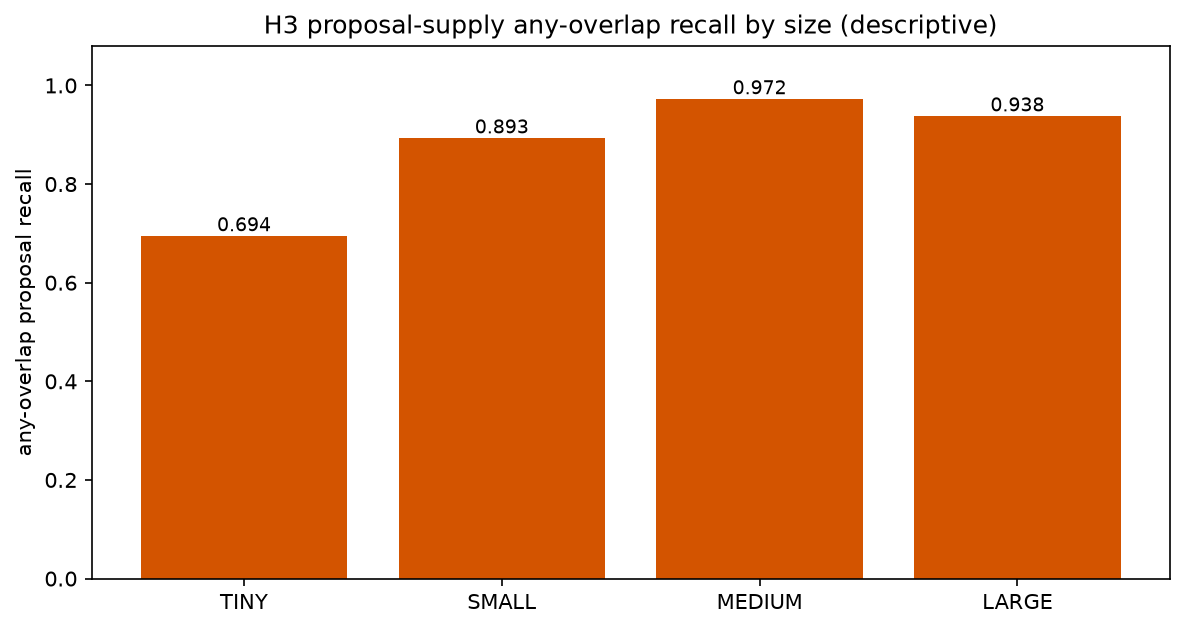

All values above are DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE / DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE


In [9]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

psum = _pd.read_csv(_TAB / 'project_evaluation_proposal_metrics_summary.csv')
_disp(psum)

h3c = _pd.read_csv(_TAB / 'h3_supply_eval_per_component.csv')
by = h3c.groupby('size_stratum').agg(n=('any_overlap', 'size'), detected=('any_overlap', 'sum')).reset_index()
by['any_overlap_recall'] = by['detected'] / by['n']
by['metric_domain'] = 'OBJECT_COMPONENT_DETECTION'; by['label'] = LBL_H3
_disp(by.round(6))

fig, ax = _plt.subplots(figsize=(8, 4.3))
order = ['TINY', 'SMALL', 'MEDIUM', 'LARGE']
vals = [float(by[by['size_stratum'] == s]['any_overlap_recall'].iloc[0]) for s in order]
ax.bar(order, vals, color='#d35400')
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)
ax.set_ylim(0, 1.08); ax.set_ylabel('any-overlap proposal recall')
ax.set_title('H3 proposal-supply any-overlap recall by size (descriptive)')
_plt.tight_layout(); _p = _FIG / 'h3_01_proposal_recall_by_size.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

print('All values above are', LBL_H3, '/', LBL)